# Structure des données et taxonomie des sprites

Ce notebook lit [`taxonomies.json`](taxonomies.json) et affiche un arbre par dimension. Les dimensions décrivent des aspects indépendants d’une image : par exemple, **la vue** indique l’angle d’observation, tandis que **la pose** décrit la position du corps. Elles ne constituent pas une seule chaîne de catégories.

Les branches regroupent les possibilités ; seuls les nœuds terminaux, indiqués en bleu, sont attribués aux images. `unknown` signifie que l’information est incertaine ; `not_applicable` indique qu’elle n’a pas de sens pour l’image. Chaque arbre est suivi d’une liste de définitions pour ses branches et ses valeurs. Modifier le JSON puis relancer les cellules actualise les arbres.


In [5]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
dataset_dir = next((p for p in (cwd, cwd / "notebook/dataset", cwd / "dataset") if (p / "taxonomies.json").is_file()), None)
if dataset_dir is None:
    raise FileNotFoundError("Ouvre le notebook depuis notebook/dataset, notebook ou la racine du projet.")
taxonomy = json.loads((dataset_dir / "taxonomies.json").read_text(encoding="utf-8"))
print(f"Taxonomie version {taxonomy['version']} · {len(taxonomy['hierarchies'])} dimensions")


Taxonomie version 3.2.0 · 10 dimensions


## Exemple : une image, ses taxonomies et sa description libre

Voici un exemple illustratif construit à partir d’un sprite préparé localement. Les valeurs incertaines sont indiquées comme `unknown` ; elles ne constituent pas une annotation validée. La description libre complète les étiquettes avec les détails visibles.


In [ ]:
EXAMPLE_IMAGE = dataset_dir.parent / "training/iris_sprite_lora_work/dataset_96/4e7203a272af59b647a90108.png"
example_labels = {
    "asset_type": "single_sprite", "subject_type": "unknown", "view": "unknown",
    "pose": "unknown", "action": "unknown", "background_type": "solid_color",
    "render_family": "pixel_art", "body_plan": "unknown", "wings": "unknown",
    "background_scene": "not_applicable",
}

def find_path(tree, value, prefix=()):
    for name, children in tree.items():
        path = (*prefix, name)
        if not children and name == value:
            return list(path)
        found = find_path(children, value, path)
        if found is not None:
            return found
    return None

paths = {key: find_path(taxonomy["hierarchies"][key], value) for key, value in example_labels.items()}
if any(path is None for path in paths.values()):
    raise ValueError("L’exemple ne correspond plus à taxonomies.json ; mets ses étiquettes à jour.")
example = {
    "image": str(EXAMPLE_IMAGE.relative_to(dataset_dir.parent)),
    "labels": example_labels,
    "taxonomy_paths": paths,
    "free_caption": "A small pixel-art figure with orange, red and blue details on a white background.",
    "review_status": "illustrative_example_not_reviewed",
}
if EXAMPLE_IMAGE.is_file():
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(plt.imread(EXAMPLE_IMAGE), interpolation="nearest")
    ax.set_title("Sprite d’exemple")
    ax.axis("off")
    plt.show()
else:
    print(f"Image d’exemple indisponible : {EXAMPLE_IMAGE}. Prépare le dataset d’entraînement pour l’afficher.")
print(json.dumps(example, ensure_ascii=False, indent=2))


## Lire les arbres

La racine nomme la dimension, les niveaux intermédiaires regroupent les concepts et les feuilles correspondent aux valeurs enregistrées. Les noms affichés sont les identifiants exacts du JSON ; les descriptions au-dessus de chaque arbre précisent quand utiliser la dimension.


### Type de fichier visuel (`asset_type`)

Organisation générale de l’image : sprite seul, planche, décor, etc.

**Application :** Pour toute image ; unknown si sa structure est incertaine.

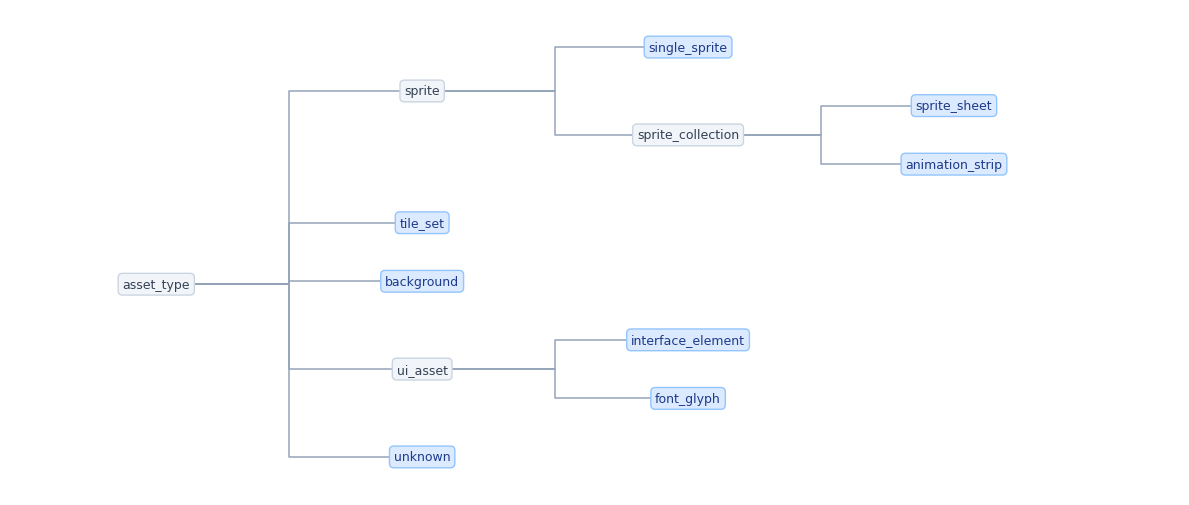

- `sprite` (branche) : Éléments graphiques représentant un ou plusieurs sprites.
  - `single_sprite` (valeur) : Une seule image ou pose de sprite, sans grille d’autres sprites.
  - `sprite_collection` (branche) : Plusieurs sprites ou frames réunis dans une même image.
    - `sprite_sheet` (valeur) : Planche contenant plusieurs sprites ou frames, pas nécessairement rangés en séquence.
    - `animation_strip` (valeur) : Bande de frames successives d’une même animation.
- `tile_set` (valeur) : Ensemble de tuiles destinées à composer des décors ou niveaux.
- `background` (valeur) : Image de décor ou de fond, plutôt qu’un sprite isolé.
- `ui_asset` (branche) : Élément destiné visuellement à une interface ou à du texte.
  - `interface_element` (valeur) : Bouton, cadre, icône d’interface ou autre élément de HUD.
  - `font_glyph` (valeur) : Glyphe ou caractère typographique isolé.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.

### Forme du sujet principal (`subject_type`)

Forme générale visible : humanoïde, animal, insecte, objet, décor ou autre. Une figure humanoïde peut être humaine, anthropomorphe ou mécanique.

**Application :** Pour toute image ; choisir une forme générale non spécifiée si les détails ne sont pas visibles, ou unknown si aucun sujet principal ne se distingue. Les formes décrivent l’apparence, pas les origines ou le rôle du sujet.

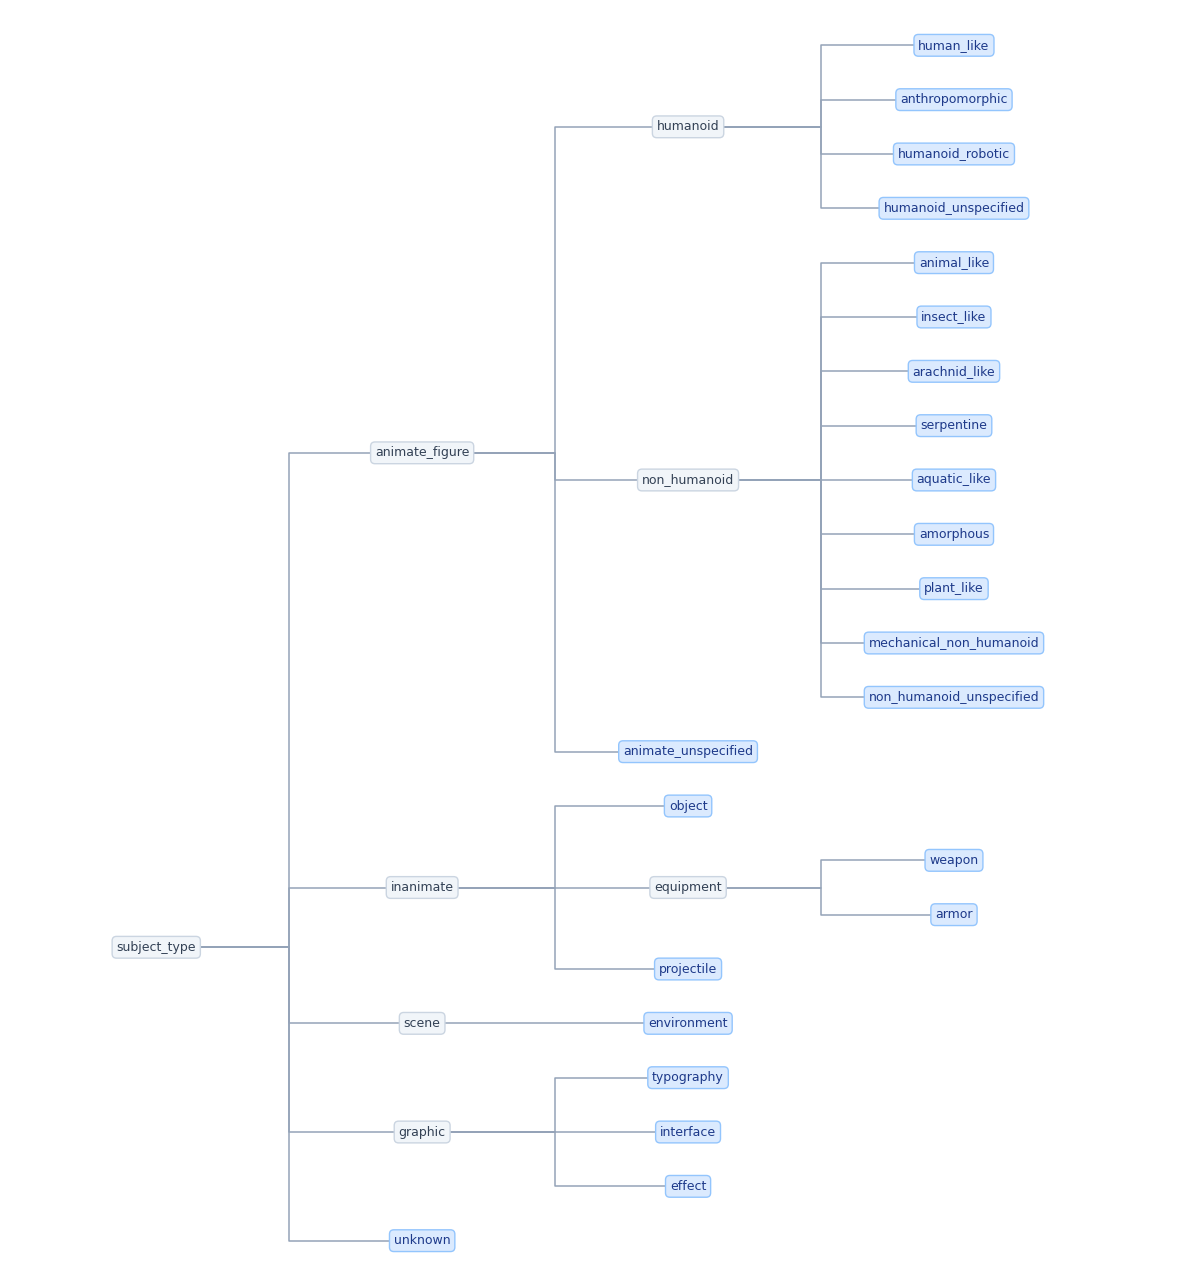

- `animate_figure` (branche) : Figure visuellement identifiable comme un être ou un personnage animé, y compris un robot.
  - `humanoid` (branche) : Figure à silhouette globalement humaine, généralement avec tête, torse et membres disposés comme ceux d’un humain.
    - `human_like` (valeur) : Humanoïde ressemblant visiblement à un humain ; les vêtements ou une armure seuls ne suffisent pas à déduire une espèce.
    - `anthropomorphic` (valeur) : Humanoïde avec des traits clairement animaux ou non humains, comme un museau ou des oreilles animales.
    - `humanoid_robotic` (valeur) : Figure humanoïde présentant des éléments mécaniques ou robotiques clairement visibles.
    - `humanoid_unspecified` (valeur) : Silhouette humanoïde reconnaissable dont les traits ne permettent pas de choisir un sous-type.
  - `non_humanoid` (branche) : Figure animée dont le corps ne ressemble pas globalement à une silhouette humaine.
    - `animal_like` (valeur) : Figure non humanoïde ressemblant visuellement à un animal terrestre ou à un oiseau.
    - `insect_like` (valeur) : Figure non humanoïde ressemblant à un insecte, par exemple avec six pattes ou des antennes visibles.
    - `arachnid_like` (valeur) : Figure non humanoïde ressemblant à une araignée ou un scorpion, par sa forme ou ses nombreuses pattes visibles.
    - `serpentine` (valeur) : Figure non humanoïde dont le corps long et souple évoque un serpent.
    - `aquatic_like` (valeur) : Figure non humanoïde évoquant visiblement un poisson ou un autre animal aquatique.
    - `amorphous` (valeur) : Figure non humanoïde sans forme corporelle rigide identifiable, comme une masse ou un slime.
    - `plant_like` (valeur) : Figure animée non humanoïde dont l’apparence évoque une plante.
    - `mechanical_non_humanoid` (valeur) : Figure non humanoïde présentant clairement une structure robotique ou mécanique.
    - `non_humanoid_unspecified` (valeur) : Figure non humanoïde identifiable, mais dont le type précis reste incertain.
  - `animate_unspecified` (valeur) : Figure animée identifiable dont la silhouette ne permet pas de choisir humanoïde ou non humanoïde.
- `inanimate` (branche) : Objet ou élément visiblement non animé.
  - `object` (valeur) : Objet isolé ne correspondant pas clairement à une catégorie plus précise.
  - `equipment` (branche) : Objet porté ou utilisé comme équipement.
    - `weapon` (valeur) : Objet identifiable comme arme, par exemple épée, arc ou lance.
    - `armor` (valeur) : Pièce d’armure ou de protection isolée.
  - `projectile` (valeur) : Projectile ou missile identifiable comme objet indépendant.
- `scene` (branche) : Scène ou décor plutôt qu’un sujet isolé.
  - `environment` (valeur) : Éléments de décor ou environnement, comme terrain, végétation ou architecture.
- `graphic` (branche) : Élément graphique, texte, interface ou effet visuel.
  - `typography` (valeur) : Texte, lettre ou symbole typographique.
  - `interface` (valeur) : Élément visuel d’interface, par exemple bouton, barre ou cadre.
  - `effect` (valeur) : Effet visuel tel que fumée, étincelle, explosion ou aura.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.

### Point de vue (`view`)

Angle sous lequel le sujet ou la scène est représenté, même sans caméra réelle.

**Application :** Pour un sujet ou une scène dont l’orientation est observable ; mixed pour plusieurs vues, not_applicable si l’angle n’a pas de sens, unknown s’il est incertain.

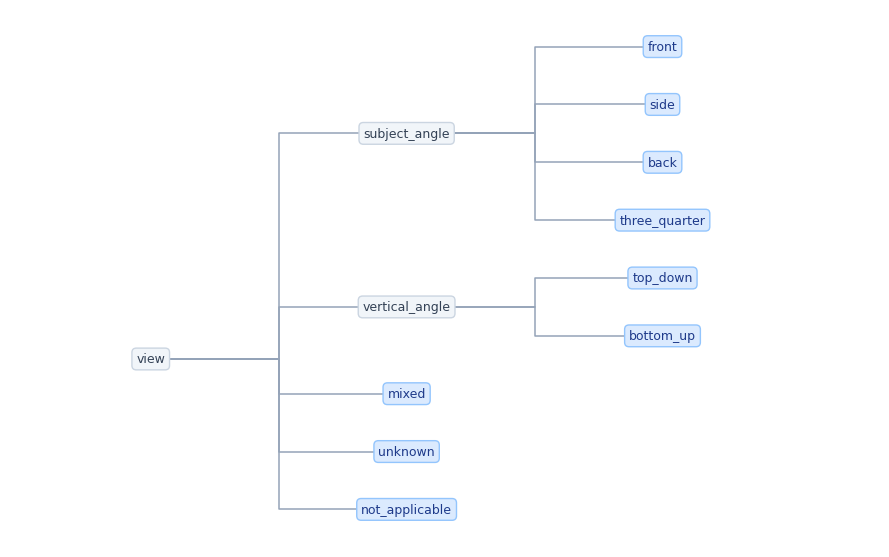

- `subject_angle` (branche) : Vue principalement définie par l’orientation horizontale du sujet.
  - `front` (valeur) : Sujet ou scène vu principalement de face.
  - `side` (valeur) : Sujet vu principalement de profil, depuis un côté.
  - `back` (valeur) : Sujet vu principalement de dos.
  - `three_quarter` (valeur) : Sujet vu en angle oblique, entre la face ou le dos et le profil.
- `vertical_angle` (branche) : Vue principalement définie par un angle au-dessus ou au-dessous du sujet.
  - `top_down` (valeur) : Vue depuis le dessus ou nettement en plongée.
  - `bottom_up` (valeur) : Vue depuis le dessous ou nettement en contre-plongée.
- `mixed` (valeur) : Plusieurs points de vue distincts sont visibles dans la même image.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.
- `not_applicable` (valeur) : Cette dimension ne s’applique pas au sujet ou au contenu de cette image.

### Pose (`pose`)

Position du corps d’une figure à un instant donné.

**Application :** Pour une figure au corps identifiable, y compris mécanique ; not_applicable pour un objet ou un décor, unknown si la pose est masquée ou ambiguë.

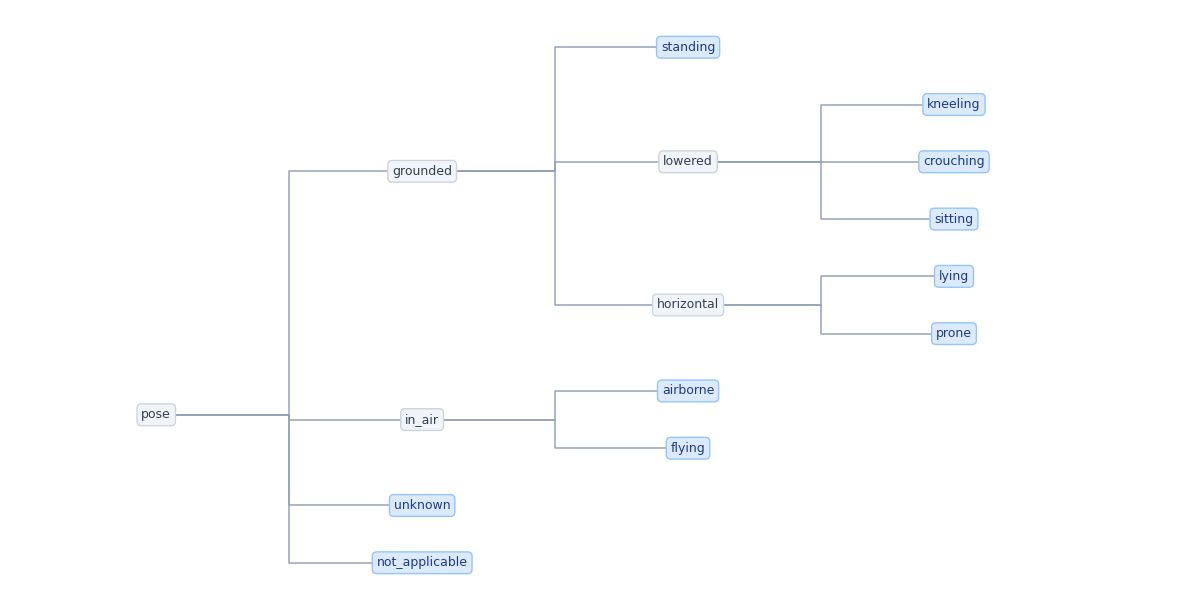

- `grounded` (branche) : Position du corps paraissant en appui sur une surface.
  - `standing` (valeur) : Corps en position debout.
  - `lowered` (branche) : Corps abaissé ou placé près de la surface.
    - `kneeling` (valeur) : Corps en appui sur un ou les deux genoux.
    - `crouching` (valeur) : Corps accroupi, les jambes repliées sous le corps.
    - `sitting` (valeur) : Corps assis, le poids reposant sur le bassin ou une surface.
  - `horizontal` (branche) : Corps allongé approximativement à l’horizontale.
    - `lying` (valeur) : Corps allongé sans orientation ventrale clairement identifiable.
    - `prone` (valeur) : Corps allongé sur le ventre ou face contre terre.
- `in_air` (branche) : Corps qui paraît ne pas être en appui sur une surface.
  - `airborne` (valeur) : Corps en suspension, sans vol clairement identifiable.
  - `flying` (valeur) : Corps dans une posture de vol visiblement identifiable.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.
- `not_applicable` (valeur) : Cette dimension ne s’applique pas au sujet ou au contenu de cette image.

### Action (`action`)

Activité identifiable à partir de l’image, distincte de la position du corps.

**Application :** Pour un sujet capable d’agir ; not_applicable si sans objet, unknown si une image fixe ne permet pas de conclure. Ne pas deviner un mouvement.

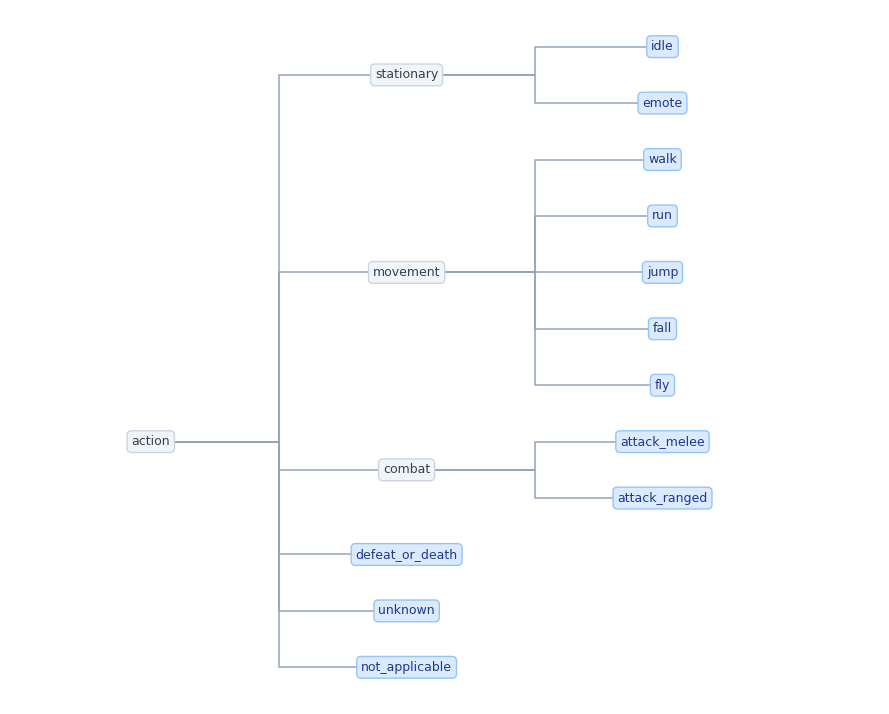

- `stationary` (branche) : Activité sans déplacement clairement visible.
  - `idle` (valeur) : Sujet manifestement au repos ; ne pas déduire une animation idle d’une image ambiguë.
  - `emote` (valeur) : Expression ou geste communicatif clairement visible.
- `movement` (branche) : Déplacement ou mouvement identifiable sur l’image.
  - `walk` (valeur) : Marche clairement suggérée par la posture ou le contexte visuel.
  - `run` (valeur) : Course clairement suggérée, distincte d’une marche.
  - `jump` (valeur) : Saut clairement identifiable.
  - `fall` (valeur) : Chute clairement identifiable.
  - `fly` (valeur) : Vol clairement identifiable comme action.
- `combat` (branche) : Action de combat clairement visible.
  - `attack_melee` (valeur) : Attaque rapprochée clairement identifiable, avec ou sans arme.
  - `attack_ranged` (valeur) : Attaque à distance clairement identifiable, par exemple tir ou lancement.
- `defeat_or_death` (valeur) : Action ou état de défaite clairement représenté ; ne pas déduire la mort d’une simple position allongée.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.
- `not_applicable` (valeur) : Cette dimension ne s’applique pas au sujet ou au contenu de cette image.

### Fond (`background_type`)

Nature du fond ou transparence du fichier.

**Application :** Pour toute image ; unknown si le fond ne peut pas être distingué.

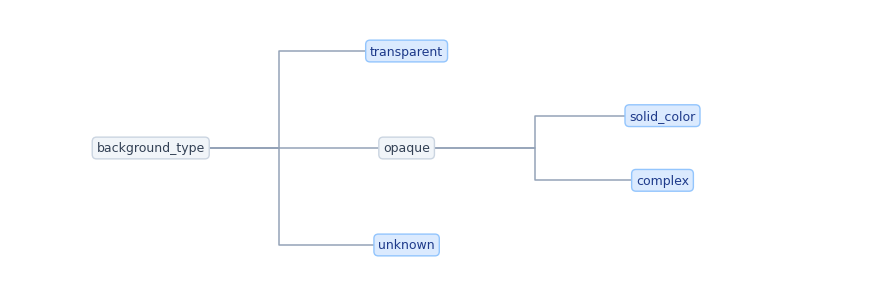

- `transparent` (valeur) : L’image contient des pixels transparents ; cette information peut provenir du canal alpha.
- `opaque` (branche) : Le fichier ne présente pas de transparence visible.
  - `solid_color` (valeur) : Fond opaque d’une seule couleur ou approximativement uni.
  - `complex` (valeur) : Fond opaque avec des motifs, objets ou décor distincts.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.

### Style de rendu (`render_family`)

Famille visuelle générale du rendu.

**Application :** Pour toute image ; unknown si le rendu est incertain.

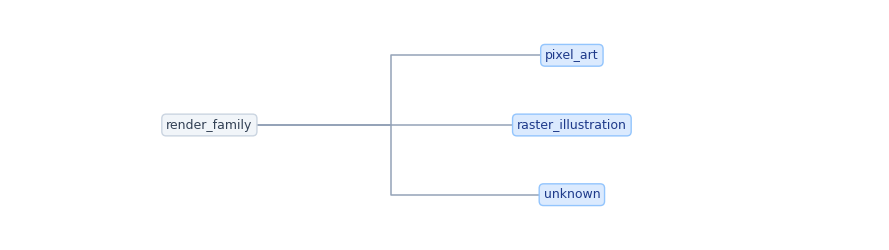

- `pixel_art` (valeur) : Rendu volontairement construit à partir de pixels visibles et de contours discrets.
- `raster_illustration` (valeur) : Illustration matricielle dont le rendu ne présente pas clairement les caractéristiques du pixel art.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.

### Structure corporelle (`body_plan`)

Organisation visible du corps et nombre de membres porteurs : bipède, quadrupède, multipède ou sans pattes.

**Application :** Pour une figure à corps identifiable, y compris un robot ; unknown si les membres sont masqués ou difficiles à compter ; not_applicable pour un objet, décor ou effet. Ne pas déduire les jambes hors champ.

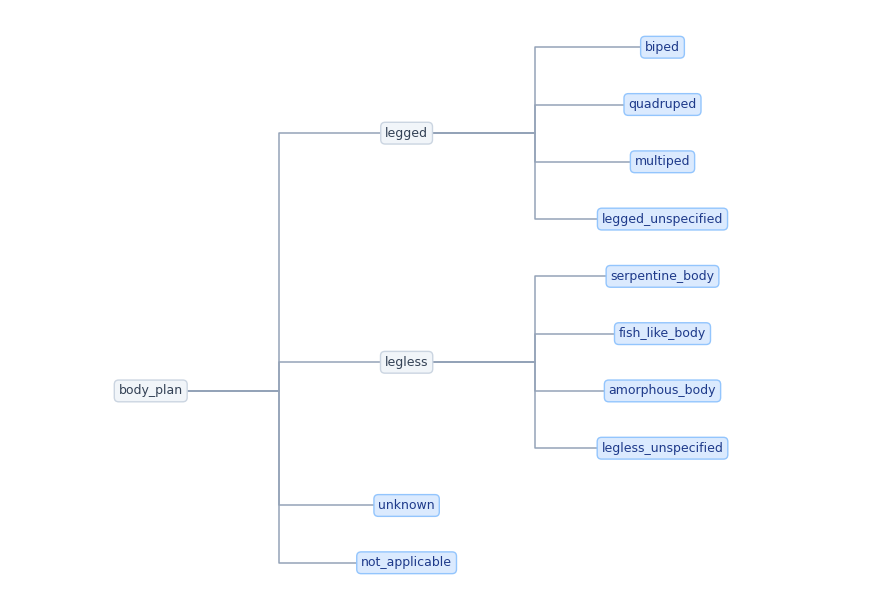

- `legged` (branche) : Figure présentant des membres porteurs ou des jambes visibles.
  - `biped` (valeur) : Deux membres porteurs visibles ; une posture humaine ne suffit pas si les jambes sont masquées.
  - `quadruped` (valeur) : Quatre membres porteurs visibles.
  - `multiped` (valeur) : Plus de quatre membres porteurs visibles.
  - `legged_unspecified` (valeur) : Des jambes ou membres porteurs sont visibles mais leur nombre reste incertain.
- `legless` (branche) : Figure dont la structure visible ne comporte pas de jambes identifiables.
  - `serpentine_body` (valeur) : Corps allongé et souple sans jambes visibles, évoquant un serpent.
  - `fish_like_body` (valeur) : Corps sans jambes visibles évoquant un poisson, éventuellement avec nageoires.
  - `amorphous_body` (valeur) : Corps sans jambes visibles et sans structure rigide identifiable.
  - `legless_unspecified` (valeur) : Corps sans jambes visibles dont la structure précise est incertaine.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.
- `not_applicable` (valeur) : Cette dimension ne s’applique pas au sujet ou au contenu de cette image.

### Ailes visibles (`wings`)

Présence visuelle d’ailes ; wings_not_visible signifie uniquement qu’aucune aile n’est visible sur cette image.

**Application :** Pour une figure dont le corps est identifiable ; unknown si le cadrage ou la résolution ne permet pas de conclure ; not_applicable pour un objet, décor ou effet.

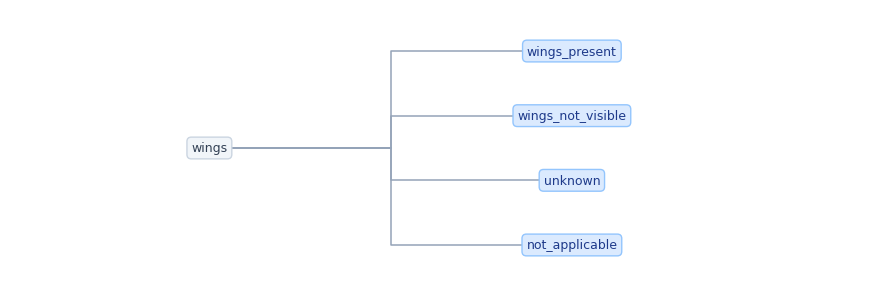

- `wings_present` (valeur) : Une ou plusieurs ailes sont clairement visibles.
- `wings_not_visible` (valeur) : Aucune aile n’est visible alors que le cadrage et la résolution permettent de l’évaluer ; ne prouve pas que le sujet n’en possède pas.
- `unknown` (valeur) : Information incertaine, masquée ou impossible à déterminer à partir de cette image.
- `not_applicable` (valeur) : Cette dimension ne s’applique pas au sujet ou au contenu de cette image.

### Décor du fond complexe (`background_scene`)

Type de décor identifiable à l’arrière-plan : milieu naturel, construction ou fond abstrait.

**Application :** Uniquement quand background_type vaut complex ; not_applicable pour un fond transparent ou uni. Pour un fond complexe non reconnaissable, choisir unknown. Ne pas supposer une forêt à partir d’une couleur verte.

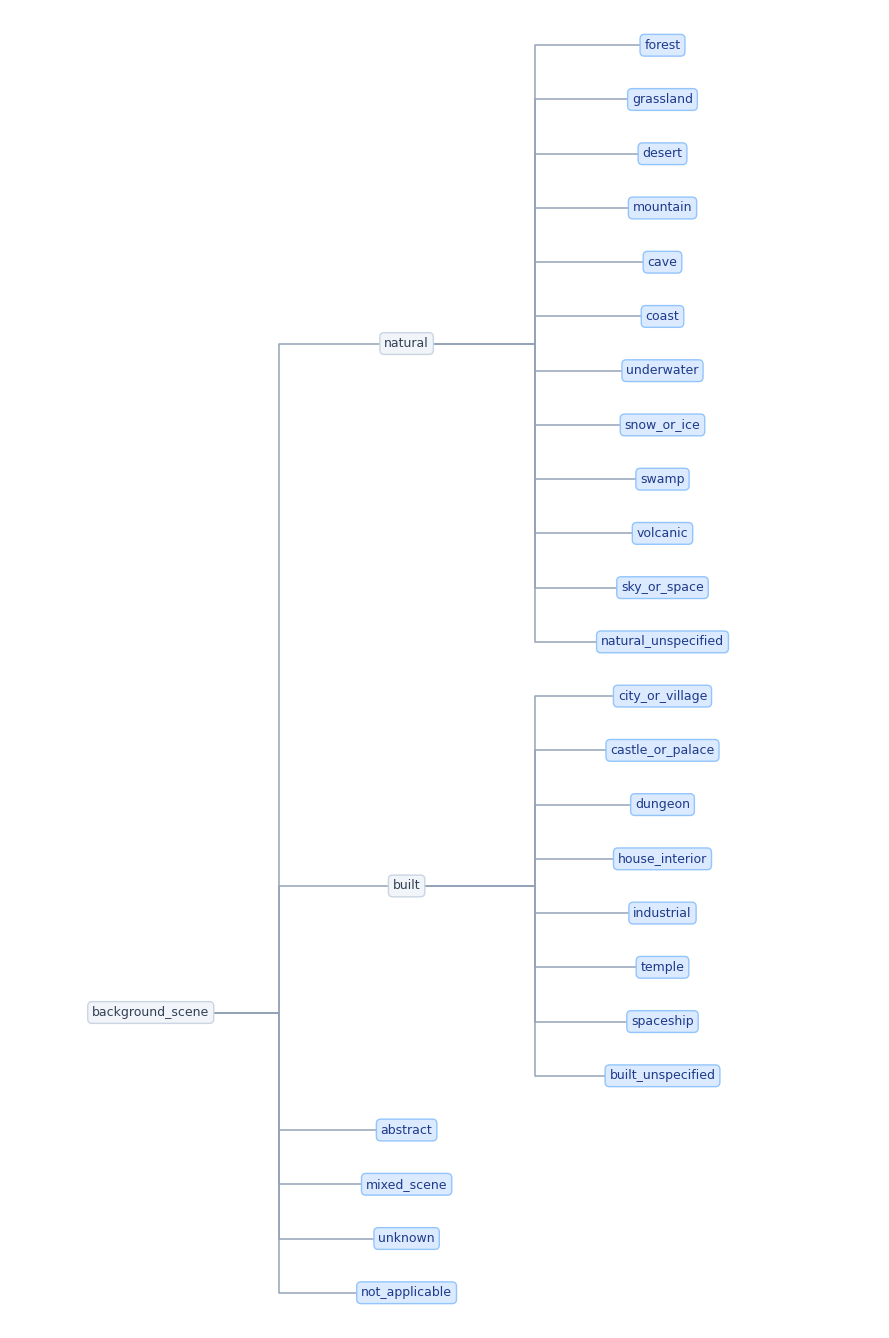

- `natural` (branche) : Décor principalement composé d’éléments naturels.
  - `forest` (valeur) : Décor avec arbres ou végétation arborée formant une forêt.
  - `grassland` (valeur) : Plaine, prairie ou champ principalement couvert d’herbe.
  - `desert` (valeur) : Décor aride, sableux ou désertique clairement identifiable.
  - `mountain` (valeur) : Paysage dominé par des montagnes ou reliefs rocheux élevés.
  - `cave` (valeur) : Intérieur souterrain naturel ou grotte reconnaissable.
  - `coast` (valeur) : Rivage, plage ou bord de mer identifiable.
  - `underwater` (valeur) : Scène représentée sous l’eau.
  - `snow_or_ice` (valeur) : Paysage dominé par la neige ou la glace.
  - `swamp` (valeur) : Marécage ou zone humide reconnaissable.
  - `volcanic` (valeur) : Décor volcanique avec lave ou signes géologiques visibles.
  - `sky_or_space` (valeur) : Ciel ouvert ou espace cosmique comme décor principal.
  - `natural_unspecified` (valeur) : Décor naturel reconnaissable mais plus précis impossible.
- `built` (branche) : Décor principalement constitué de constructions.
  - `city_or_village` (valeur) : Rue, bâtiments ou ensemble urbain ou villageois.
  - `castle_or_palace` (valeur) : Château, palais ou architecture clairement associée.
  - `dungeon` (valeur) : Intérieur construit souterrain de type donjon, cellule ou fortification.
  - `house_interior` (valeur) : Pièce ou intérieur domestique identifiable.
  - `industrial` (valeur) : Usine, atelier industriel ou structures mécaniques industrielles.
  - `temple` (valeur) : Temple ou édifice religieux identifiable visuellement.
  - `spaceship` (valeur) : Intérieur ou structure évoquant clairement un vaisseau spatial.
  - `built_unspecified` (valeur) : Décor construit reconnaissable mais plus précis impossible.
- `abstract` (valeur) : Fond complexe non figuratif, motif ou composition abstraite.
- `mixed_scene` (valeur) : Plusieurs décors distincts sont visibles sans type dominant unique.
- `unknown` (valeur) : Fond complexe mais décor incertain ou impossible à identifier.
- `not_applicable` (valeur) : Fond transparent ou uni : aucun décor complexe à qualifier.

In [6]:
def draw_tree(dimension, tree):
    # Place leaves on separate rows, then center each branch above its children.
    nodes, edges = [], []
    next_row = 0
    def visit(name, children, depth):
        nonlocal next_row
        positions = []
        for child, subtree in children.items():
            child_y = visit(child, subtree, depth + 1)
            positions.append((child, child_y))
        if positions:
            y = sum(pos for _, pos in positions) / len(positions)
            edges.extend((depth, y, depth + 1, child_y) for _, child_y in positions)
        else:
            y = next_row
            next_row += 1
        nodes.append((name, depth, y, not bool(children)))
        return y
    visit(dimension, tree, 0)
    depth_max = max(depth for _, depth, _, _ in nodes)
    fig, ax = plt.subplots(figsize=(max(9, (depth_max + 1) * 3.0), max(2.6, next_row * 0.52 + 1.0)))
    ax.set_xlim(-0.55, depth_max + 0.85)
    ax.set_ylim(next_row - 0.35, -0.65)
    ax.axis("off")
    for x1, y1, x2, y2 in edges:
        mid = (x1 + x2) / 2
        ax.plot([x1, mid, mid, x2], [y1, y1, y2, y2], color="#94a3b8", lw=1.1, zorder=1)
    for name, x, y, is_leaf in nodes:
        ax.text(x, y, name, ha="center", va="center", fontsize=9,
                color="#1e3a8a" if is_leaf else "#334155",
                bbox={"boxstyle": "round,pad=0.35", "facecolor": "#dbeafe" if is_leaf else "#f1f5f9", "edgecolor": "#93c5fd" if is_leaf else "#cbd5e1"}, zorder=2)
    plt.tight_layout()
    plt.show()

for dimension, tree in taxonomy["hierarchies"].items():
    info = taxonomy["dimensions"][dimension]
    display(Markdown(f"### {info['label']} (`{dimension}`)\n\n{info['definition']}\n\n**Application :** {info['applicability']}"))
    draw_tree(dimension, tree)
    def describe_nodes(nodes, depth=0):
        lines = []
        for name, children in nodes.items():
            kind = "branche" if children else "valeur"
            lines.append(f"{'  ' * depth}- `{name}` ({kind}) : {taxonomy['value_descriptions'][dimension][name]}")
            lines.extend(describe_nodes(children, depth + 1))
        return lines
    display(Markdown("\n".join(describe_nodes(tree))))
